Logistic regression could not separate the two planted epochs, because its boundary is a
straight line. A neural network fixes that by stacking linear layers with a **non-linear
function between them**.

The non-linearity is the whole point. Two linear layers in a row collapse:

$$W_2(W_1\mathbf{x}) = (W_2W_1)\mathbf{x} = W\mathbf{x}$$

&mdash; still a single linear map, however many layers you add. Insert $\sigma$ between them
and that collapse becomes impossible.

Training needs the gradient of the loss with respect to every weight, and computing those
one at a time would be hopeless. **Backpropagation** gets all of them in a single backward
pass by applying the chain rule and reusing shared work.

Below: the forward pass with every matrix printed, backpropagation derived and computed by
hand, and &mdash; the check that matters &mdash; every analytic gradient compared against a
numerical finite-difference estimate.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)
np.set_printoptions(precision=4, suppress=True, linewidth=140)


def banner(title, ch="="):
    print(ch * 78)
    print(f"  {title}")
    print(ch * 78)


def step(label):
    print()
    print(label)
    print("=" * 78)


def check(manual, from_array, label="MATCH"):
    ok = np.allclose(manual, from_array)
    print(f"      = {manual:+.6f}   |  from array: {from_array:+.6f}   |  {label}: {ok}")
    return ok


def expand(u, v, per_line=4):
    """Write a dot product out term by term."""
    terms = [f"({a:+.4f})*({b:+.4f})" for a, b in zip(u, v)]
    lines, out = [], ""
    for i, t in enumerate(terms):
        out += t + (" + " if i < len(terms) - 1 else "")
        if (i + 1) % per_line == 0:
            lines.append(out); out = ""
    if out:
        lines.append(out)
    return "\n      ".join(lines)


def show_matrix(M, name="M", rows=None, cols=None, fmt="{:+8.3f}", max_cols=14):
    M = np.asarray(M)
    if M.ndim == 1:
        M = M[None, :]
    cut = M.shape[1] > max_cols
    Ms = M[:, :max_cols] if cut else M
    print(f"{name} {np.asarray(M).shape}" +
          (f"   [first {max_cols} of {M.shape[1]} columns]" if cut else "") + " =")
    if cols is not None:
        head = "".join(f"{str(c):>10}" for c in (cols[:max_cols] if cut else cols))
        print(" " * 13 + head)
    for r in range(Ms.shape[0]):
        lab = f"{str(rows[r]):>10} | " if rows is not None else f"{r:>10} | "
        print("   " + lab + "  ".join(fmt.format(v) for v in Ms[r]))


def show_matmul(A, B, C, na="A", nb="B", nc="C", i=0, j=0,
                rows_A=None, note=None, max_cols=14):
    """Print both operands of A @ B = C, then verify one element by hand."""
    A, B, C = np.asarray(A), np.asarray(B), np.asarray(C)
    banner(f"{na} {A.shape}   @   {nb} {B.shape}   =   {nc} {C.shape}")
    print(f"  shape rule: ({A.shape[0]} x {A.shape[1]}) @ ({B.shape[0]} x {B.shape[1]})"
          f" -> ({A.shape[0]} x {B.shape[1]})   inner dim {A.shape[1]} cancels")
    if note:
        print(f"  {note}")
    print("=" * 78)
    print()
    show_matrix(A, na, rows_A, max_cols=max_cols)
    print()
    show_matrix(B, nb, max_cols=max_cols)
    print()
    show_matrix(C, nc, rows_A, max_cols=max_cols)
    print(f"\n  worked element  {nc}[{i},{j}]  =  row {i} of {na}  .  column {j} of {nb}")
    print(f"      row {i} of {na} = {np.round(A[i], 4)}")
    print(f"      col {j} of {nb} = {np.round(B[:, j], 4)}")
    print(f"      {expand(A[i], B[:, j])}")
    check(float(A[i] @ B[:, j]), float(C[i, j]))


def show_elementwise(A, B, C, na, nb, nc, op="+", rows=None):
    A, B, C = np.asarray(A), np.asarray(B), np.asarray(C)
    banner(f"{nc} = {na} {op} {nb}      all three are {A.shape} - element-wise")
    for r in range(A.shape[0]):
        lab = f"{rows[r]:>10}" if rows is not None else f"{r:>10}"
        print(f"\n{lab} |")
        print("   " + f"{na:>14}: " + "  ".join(f"{v:+8.3f}" for v in A[r]))
        print("   " + f"{nb:>14}: " + "  ".join(f"{v:+8.3f}" for v in B[r]))
        print("   " + f"{nc:>14}: " + "  ".join(f"{v:+8.3f}" for v in C[r]))
    print(f"\n  check [0,0]: {A[0,0]:+.6f} {op} {B[0,0]:+.6f} = {C[0,0]:+.6f}   "
          f"MATCH: {np.isclose(A[0,0] + B[0,0] if op == '+' else A[0,0] - B[0,0], C[0,0])}")


print("Display helpers ready: banner, step, check, expand, show_matrix, "
      "show_matmul, show_elementwise.")

Display helpers ready: banner, step, check, expand, show_matrix, show_matmul, show_elementwise.


In [2]:
def draw_network(layer_sizes, Ws, bs, title="", node_values=None,
                 layer_names=None, node_labels=None, show_weights=True,
                 ax=None, wmax=None, figsize=None, fontsize=8):
    """Draw a feed-forward network with its weights written on the edges.

    layer_sizes : e.g. [2, 4, 1]
    Ws, bs      : lists of weight matrices / bias vectors
    node_values : optional list of per-layer arrays to print inside the nodes
    """
    L = len(layer_sizes)
    own = ax is None
    if own:
        figsize = figsize or (3.0 * L + 3.0, 1.75 * max(layer_sizes) + 2.0)
        fig, ax = plt.subplots(figsize=figsize)

    # vertical positions, each layer centred on 0. VSPACE must leave room for
    # the node label above each circle (radius .42), or labels collide.
    VSPACE = 1.6
    pos = []
    for li, nsz in enumerate(layer_sizes):
        ys = np.linspace(-(nsz - 1) / 2.0, (nsz - 1) / 2.0, nsz) * VSPACE
        pos.append([(li * 3.0, yy) for yy in ys])

    if wmax is None:
        wmax = max(np.abs(W).max() for W in Ws) if Ws else 1.0
    wmax = max(wmax, 1e-9)

    for li, W in enumerate(Ws):
        for a in range(W.shape[0]):
            for b in range(W.shape[1]):
                wv = W[a, b]
                x0, y0 = pos[li][a]
                x1, y1 = pos[li + 1][b]
                lw = 0.4 + 4.6 * abs(wv) / wmax
                col = "#1d4ed8" if wv >= 0 else "#b91c1c"
                ax.plot([x0 + .42, x1 - .42], [y0, y1], color=col, lw=lw,
                        alpha=.75, zorder=1, solid_capstyle="round")
                if show_weights:
                    t = 0.5
                    ax.text(x0 + .42 + t * (x1 - x0 - .84), y0 + t * (y1 - y0),
                            f"{wv:+.2f}", fontsize=fontsize - 1.4, color=col,
                            ha="center", va="center", zorder=4,
                            bbox=dict(boxstyle="round,pad=0.10", fc="white",
                                      ec="none", alpha=.82))

    for li, nsz in enumerate(layer_sizes):
        for a in range(nsz):
            x, yy = pos[li][a]
            face = "#e0e7ff" if li == 0 else ("#dcfce7" if li == L - 1 else "#fef3c7")
            ax.add_patch(plt.Circle((x, yy), .42, fc=face, ec="#334155",
                                    lw=1.5, zorder=3))
            inner = ""
            if node_values is not None and node_values[li] is not None:
                inner = f"{node_values[li][a]:+.2f}"
            elif li > 0 and bs and bs[li - 1] is not None:
                inner = f"b{bs[li-1].ravel()[a]:+.2f}"
            if inner:
                ax.text(x, yy, inner, ha="center", va="center",
                        fontsize=fontsize - 1, zorder=5, family="monospace")
            if node_labels and node_labels[li]:
                lab = str(node_labels[li][a])
                if li == 0:                      # inputs: label to the left
                    ax.text(x - .55, yy, lab, ha="right", va="center",
                            fontsize=fontsize - .5, color="#334155", zorder=5)
                elif li == L - 1:                # output: label to the right
                    ax.text(x + .55, yy, lab, ha="left", va="center",
                            fontsize=fontsize - .5, color="#334155", zorder=5)
                else:                            # hidden: above, in the gap
                    ax.text(x, yy + .52, lab, ha="center", va="bottom",
                            fontsize=fontsize - .5, color="#334155", zorder=5)

    if layer_names:
        top = max(max(abs(p[1]) for p in lay) for lay in pos) + 1.25
        for li, nm in enumerate(layer_names):
            ax.text(li * 3.0, top, nm, ha="center", va="bottom",
                    fontsize=fontsize + 1.2, fontweight="bold", color="#1e293b")

    allx = [p[0] for lay in pos for p in lay]
    ally = [p[1] for lay in pos for p in lay]
    ax.set_xlim(min(allx) - 1.0, max(allx) + 1.0)
    ax.set_ylim(min(ally) - 1.1, max(ally) + 2.1)
    ax.axis("off")
    if title:
        ax.set_title(title, fontsize=11, fontweight="bold", pad=10)
    if own:
        plt.tight_layout(); plt.show()
    return ax


print("Network diagram helper ready: draw_network(layer_sizes, Ws, bs, ...).")
print("   edge width = |weight|,  blue = positive,  red = negative")

Network diagram helper ready: draw_network(layer_sizes, Ws, bs, ...).
   edge width = |weight|,  blue = positive,  red = negative


---
# 1. The Data and the Architecture

The same 20 EEG epochs. A deliberately tiny network so every matrix fits on the page:

$$\underbrace{\mathbf{x}}_{2} \;\xrightarrow{W_1, \mathbf{b}_1}\; \underbrace{\mathbf{z}_1 \to \mathbf{a}_1}_{4 \text{ hidden, tanh}}
\;\xrightarrow{W_2, \mathbf{b}_2}\; \underbrace{z_2 \to \hat{y}}_{1 \text{ output, sigmoid}}$$

Parameter count: $W_1$ is $2\times4 = 8$, $\mathbf{b}_1$ is 4, $W_2$ is $4\times1 = 4$,
$\mathbf{b}_2$ is 1 &mdash; **17 numbers in total**.

In [3]:
# ----------------------------------------------------------------------------
#  20 EEG epochs, two features, two classes. Small enough to print in full,
#  and deliberately NOT perfectly separable.
# ----------------------------------------------------------------------------
feat2 = ["spike_rate", "line_length"]

P = np.array([
    [1.0, 12.0], [1.6, 15.0], [0.7, 11.0], [2.1, 18.0], [1.3, 14.0],
    [2.6, 21.0], [0.9, 16.0], [1.9, 13.0], [3.1, 24.0], [2.3, 17.0],
    [6.2, 41.0], [7.1, 47.0], [5.4, 38.0], [8.0, 52.0], [6.7, 44.0],
    [5.9, 49.0], [7.6, 39.0], [6.0, 35.0], [4.7, 43.0], [8.3, 46.0],
])
t2 = np.array([0]*10 + [1]*10)

# two deliberate overlaps, so no straight line separates the data perfectly
P[9]  = [4.4, 33.0]      # a class-0 epoch pushed into class-1 territory
t2[9] = 0
P[18] = [3.6, 27.0]      # a class-1 epoch pushed down toward class 0
t2[18] = 1

n2 = len(P)
ep_ids = [f"ep{i:02d}" for i in range(n2)]
cls_names = ["no seizure", "seizure"]

print(f"{n2} epochs x {P.shape[1]} features, classes {np.bincount(t2).tolist()}\n")
hdr = f"{'id':>6}  {feat2[0]:>11}  {feat2[1]:>12}  {'class':>6}  {'label':>12}"
print(hdr); print("-" * len(hdr))
for i in range(n2):
    print(f"{ep_ids[i]:>6}  {P[i,0]:>11.1f}  {P[i,1]:>12.1f}  {t2[i]:>6}  "
          f"{cls_names[t2[i]]:>12}")
print("-" * len(hdr))
print(f"\nfeature means : {np.round(P.mean(axis=0), 3)}")
print(f"feature stds  : {np.round(P.std(axis=0), 3)}")
print(f"\nNote the scales: {feat2[1]} spans ~{P[:,1].ptp() if hasattr(P[:,1],'ptp') else np.ptp(P[:,1]):.0f} "
      f"while {feat2[0]} spans ~{np.ptp(P[:,0]):.0f}.")
print("Any algorithm that measures DISTANCE will be dominated by the larger one")
print("unless the features are scaled - that matters for KNN and SVM below.")

20 epochs x 2 features, classes [10, 10]

    id   spike_rate   line_length   class         label
-------------------------------------------------------
  ep00          1.0          12.0       0    no seizure
  ep01          1.6          15.0       0    no seizure
  ep02          0.7          11.0       0    no seizure
  ep03          2.1          18.0       0    no seizure
  ep04          1.3          14.0       0    no seizure
  ep05          2.6          21.0       0    no seizure
  ep06          0.9          16.0       0    no seizure
  ep07          1.9          13.0       0    no seizure
  ep08          3.1          24.0       0    no seizure
  ep09          4.4          33.0       0    no seizure
  ep10          6.2          41.0       1       seizure
  ep11          7.1          47.0       1       seizure
  ep12          5.4          38.0       1       seizure
  ep13          8.0          52.0       1       seizure
  ep14          6.7          44.0       1       seizure
  ep15

In [4]:
def plot2d(ax=None, scaled=False, title="", legend=True):
    A = Pz if scaled else P
    own = ax is None
    if own:
        fig, ax = plt.subplots(figsize=(7, 5))
    for c, (col, mk) in enumerate([("steelblue", "o"), ("crimson", "^")]):
        m = t2 == c
        ax.scatter(A[m, 0], A[m, 1], c=col, marker=mk, s=90, edgecolor="k",
                   label=cls_names[c], zorder=3)
    ax.set(xlabel=feat2[0] + (" (scaled)" if scaled else ""),
           ylabel=feat2[1] + (" (scaled)" if scaled else ""), title=title)
    if legend:
        ax.legend(fontsize=8)
    ax.grid(alpha=.3)
    return ax

Pz = (P - P.mean(axis=0)) / P.std(axis=0)
Y = t2.reshape(-1, 1).astype(float)

N_IN, N_HID, N_OUT = 2, 4, 1

rng = np.random.default_rng(7)
def init_params(seed=7):
    r = np.random.default_rng(seed)
    # Xavier/Glorot: keeps activation variance stable across a layer
    W1 = r.uniform(-np.sqrt(6/(N_IN+N_HID)), np.sqrt(6/(N_IN+N_HID)), (N_IN, N_HID))
    b1 = np.zeros((1, N_HID))
    W2 = r.uniform(-np.sqrt(6/(N_HID+N_OUT)), np.sqrt(6/(N_HID+N_OUT)), (N_HID, N_OUT))
    b2 = np.zeros((1, N_OUT))
    return W1, b1, W2, b2

W1, b1, W2, b2 = init_params()
n_params = W1.size + b1.size + W2.size + b2.size
print(f"architecture: {N_IN} -> {N_HID} (tanh) -> {N_OUT} (sigmoid)")
print(f"parameters: W1 {W1.shape} + b1 {b1.shape} + W2 {W2.shape} + b2 {b2.shape}"
      f" = {n_params}\n")
show_matrix(W1, "W1 (initial)", rows=feat2, cols=[f"h{j}" for j in range(N_HID)])
print()
show_matrix(W2.T, "W2^T (initial)", rows=["out"], cols=[f"h{j}" for j in range(N_HID)])
print(f"\nXavier init draws from U(-a, a) with a = sqrt(6/(fan_in+fan_out)):")
print(f"   layer 1: a = sqrt(6/({N_IN}+{N_HID})) = {np.sqrt(6/(N_IN+N_HID)):.6f}")
print(f"   layer 2: a = sqrt(6/({N_HID}+{N_OUT})) = {np.sqrt(6/(N_HID+N_OUT)):.6f}")
print(f"\nBiases start at zero; weights must NOT, or every hidden unit would compute")
print(f"the same thing forever and the layer would be worth one unit.")

architecture: 2 -> 4 (tanh) -> 1 (sigmoid)
parameters: W1 (2, 4) + b1 (1, 4) + W2 (4, 1) + b2 (1, 1) = 17

W1 (initial) (2, 4) =
                     h0        h1        h2        h3
   spike_rate |   +0.250    +0.794    +0.551    -0.550
   line_length |   -0.400    +0.747    -0.989    +0.642

W2^T (initial) (1, 4) =
                     h0        h1        h2        h3
          out |   +0.651    -0.070    -0.432    -0.485

Xavier init draws from U(-a, a) with a = sqrt(6/(fan_in+fan_out)):
   layer 1: a = sqrt(6/(2+4)) = 1.000000
   layer 2: a = sqrt(6/(4+1)) = 1.095445

Biases start at zero; weights must NOT, or every hidden unit would compute
the same thing forever and the layer would be worth one unit.


---
# 2. The Forward Pass

$$\mathbf{z}_1 = XW_1 + \mathbf{b}_1 \qquad \mathbf{a}_1 = \tanh(\mathbf{z}_1)$$
$$z_2 = \mathbf{a}_1W_2 + b_2 \qquad \hat{y} = \sigma(z_2)$$

and the loss is binary cross-entropy, the same one derived in the Logistic Regression
walkthrough:

$$\mathcal{L} = -\frac{1}{n}\sum_i\big[y_i\log\hat{y}_i + (1-y_i)\log(1-\hat{y}_i)\big]$$

In [5]:
def sigmoid(z):
    return np.where(z >= 0, 1/(1+np.exp(-np.abs(z))),
                    np.exp(-np.abs(z))/(1+np.exp(-np.abs(z))))

def forward(Xm, W1, b1, W2, b2):
    z1 = Xm @ W1 + b1
    a1 = np.tanh(z1)
    z2 = a1 @ W2 + b2
    yh = sigmoid(z2)
    return z1, a1, z2, yh

def bce(yh, Yv):
    eps = 1e-12
    return float(-np.mean(Yv*np.log(yh+eps) + (1-Yv)*np.log(1-yh+eps)))

z1, a1, z2, yh = forward(Pz, W1, b1, W2, b2)

print("STEP 1 : z1 = X W1 + b1")
print("=" * 78)
show_matmul(Pz[:6], W1, (Pz @ W1)[:6], "X (first 6 rows)", "W1", "X W1",
            rows_A=ep_ids[:6], note=f"({n2},{N_IN}) @ ({N_IN},{N_HID}) -> ({n2},{N_HID})")
print(f"\n   then add b1 = {np.round(b1[0], 4)} to every row")

print("\n\nSTEP 2 : a1 = tanh(z1)")
print("=" * 78)
show_matrix(z1[:6], "z1 (first 6)", rows=ep_ids[:6], cols=[f"h{j}" for j in range(N_HID)])
print()
show_matrix(a1[:6], "a1 = tanh(z1)", rows=ep_ids[:6], cols=[f"h{j}" for j in range(N_HID)])
print(f"\n   tanh squashes into (-1, 1): a1 range [{a1.min():+.4f}, {a1.max():+.4f}]")
print(f"   worked element a1[0,0] = tanh({z1[0,0]:+.6f}) = {np.tanh(z1[0,0]):+.6f}   "
      f"MATCH: {np.isclose(np.tanh(z1[0,0]), a1[0,0])}")

print("\n\nSTEP 3 : z2 = a1 W2 + b2,   y_hat = sigmoid(z2)")
print("=" * 78)
show_matmul(a1[:6], W2, (a1 @ W2)[:6], "a1 (first 6)", "W2", "a1 W2",
            rows_A=ep_ids[:6])
print(f"\n   y_hat[0] = sigmoid({z2[0,0]:+.6f}) = {yh[0,0]:.6f}")
print(f"\nloss at initialisation = {bce(yh, Y):.6f}")
print(f"   (a model predicting 0.5 for everything would score {-np.log(0.5):.6f})")

STEP 1 : z1 = X W1 + b1
  X (first 6 rows) (6, 2)   @   W1 (2, 4)   =   X W1 (6, 4)
  shape rule: (6 x 2) @ (2 x 4) -> (6 x 4)   inner dim 2 cancels
  (20,2) @ (2,4) -> (20,4)

X (first 6 rows) (6, 2) =
         ep00 |   -1.256    -1.287
         ep01 |   -1.022    -1.069
         ep02 |   -1.373    -1.359
         ep03 |   -0.827    -0.852
         ep04 |   -1.139    -1.142
         ep05 |   -0.632    -0.634

W1 (2, 4) =
            0 |   +0.250    +0.794    +0.551    -0.550
            1 |   -0.400    +0.747    -0.989    +0.642

X W1 (6, 4) =
         ep00 |   +0.200    -1.959    +0.581    -0.136
         ep01 |   +0.172    -1.611    +0.495    -0.125
         ep02 |   +0.200    -2.106    +0.588    -0.119
         ep03 |   +0.134    -1.293    +0.387    -0.093
         ep04 |   +0.171    -1.758    +0.502    -0.108
         ep05 |   +0.095    -0.976    +0.279    -0.060

  worked element  X W1[0,0]  =  row 0 of X (first 6 rows)  .  column 0 of W1
      row 0 of X (first 6 rows) = [-1.256

---
# 3. Backpropagation

The derivation is the chain rule applied layer by layer, working backwards. Two facts
make it short.

**Fact 1 &mdash; the output layer collapses.** Sigmoid with cross-entropy gives exactly the
same cancellation as in logistic regression:

$$\frac{\partial \mathcal{L}}{\partial z_2} = \hat{y} - y \;\equiv\; \delta_2$$

**Fact 2 &mdash; tanh has a cheap derivative.** $\tanh'(z) = 1 - \tanh^2(z) = 1 - a_1^2$, so
the forward activations are reused rather than recomputed.

Propagating $\delta_2$ backwards:

$$\boxed{\;\delta_2 = \hat{y}-y\;}
\qquad
\frac{\partial\mathcal{L}}{\partial W_2} = \frac{1}{n}\mathbf{a}_1^\top\delta_2
\qquad
\frac{\partial\mathcal{L}}{\partial b_2} = \frac{1}{n}\sum_i \delta_2$$

$$\boxed{\;\delta_1 = (\delta_2 W_2^\top)\odot(1 - \mathbf{a}_1^2)\;}
\qquad
\frac{\partial\mathcal{L}}{\partial W_1} = \frac{1}{n}X^\top\delta_1
\qquad
\frac{\partial\mathcal{L}}{\partial b_1} = \frac{1}{n}\sum_i \delta_1$$

Read $\delta$ as "how much this pre-activation is to blame". The whole algorithm is:
compute blame at the output, pass it back through $W^\top$, scale it by the local
derivative, repeat.

In [6]:
def backward(Xm, Yv, z1, a1, z2, yh, W2):
    n = len(Xm)
    d2 = (yh - Yv) / n                       # includes the 1/n from the mean
    gW2 = a1.T @ d2
    gb2 = d2.sum(axis=0, keepdims=True)
    d1 = (d2 @ W2.T) * (1 - a1**2)
    gW1 = Xm.T @ d1
    gb1 = d1.sum(axis=0, keepdims=True)
    return gW1, gb1, gW2, gb2, d1, d2

gW1, gb1, gW2, gb2, d1, d2 = backward(Pz, Y, z1, a1, z2, yh, W2)

print("delta_2 = (y_hat - y) / n     'blame' at the output\n")
print(f"{'id':>6}  {'y_hat':>10}  {'y':>4}  {'y_hat - y':>11}  {'delta_2':>11}")
print("-" * 50)
for i in range(8):
    print(f"{ep_ids[i]:>6}  {yh[i,0]:>10.6f}  {int(Y[i,0]):>4}  "
          f"{yh[i,0]-Y[i,0]:>11.6f}  {d2[i,0]:>11.6f}")
print(f"{'...':>6}")
print("-" * 50)

print(f"\n\ndelta_1 = (delta_2 W2^T) * (1 - a1^2)     blame pushed back one layer\n")
back_sig = d2 @ W2.T
print(f"   step a: delta_2 @ W2^T  -> distributes blame by connection strength")
show_matrix(back_sig[:5], "delta_2 @ W2^T", rows=ep_ids[:5],
            cols=[f"h{j}" for j in range(N_HID)], fmt="{:+11.7f}")
print(f"\n   step b: multiply by the LOCAL derivative 1 - a1^2")
show_matrix((1 - a1**2)[:5], "1 - a1^2  (tanh')", rows=ep_ids[:5],
            cols=[f"h{j}" for j in range(N_HID)], fmt="{:+11.7f}")
print()
show_matrix(d1[:5], "delta_1", rows=ep_ids[:5],
            cols=[f"h{j}" for j in range(N_HID)], fmt="{:+11.7f}")

print(f"\n   worked element delta_1[0,0]:")
print(f"      = ({back_sig[0,0]:+.8f}) * (1 - ({a1[0,0]:+.6f})^2)")
print(f"      = ({back_sig[0,0]:+.8f}) * ({1-a1[0,0]**2:+.8f})")
print(f"      = {back_sig[0,0]*(1-a1[0,0]**2):+.10f}")
print(f"      from the array: {d1[0,0]:+.10f}   "
      f"MATCH: {np.isclose(back_sig[0,0]*(1-a1[0,0]**2), d1[0,0])}")

print(f"\n\ngradients\n")
show_matrix(gW1, "dL/dW1", rows=feat2, cols=[f"h{j}" for j in range(N_HID)],
            fmt="{:+12.8f}")
print()
show_matrix(gW2.T, "dL/dW2^T", rows=["out"], cols=[f"h{j}" for j in range(N_HID)],
            fmt="{:+12.8f}")
print(f"\ndL/db1 = {np.round(gb1[0], 8)}")
print(f"dL/db2 = {np.round(gb2[0], 8)}")

delta_2 = (y_hat - y) / n     'blame' at the output

    id       y_hat     y    y_hat - y      delta_2
--------------------------------------------------
  ep00    0.509010     0     0.509010     0.025450
  ep01    0.509614     0     0.509614     0.025481
  ep02    0.506454     0     0.506454     0.025323
  ep03    0.508158     0     0.508158     0.025408
  ep04    0.507163     0     0.507163     0.025358
  ep05    0.506610     0     0.506610     0.025331
  ep06    0.491352     0     0.491352     0.024568
  ep07    0.525498     0     0.525498     0.026275
   ...
--------------------------------------------------


delta_1 = (delta_2 W2^T) * (1 - a1^2)     blame pushed back one layer

   step a: delta_2 @ W2^T  -> distributes blame by connection strength
delta_2 @ W2^T (5, 4) =
                     h0        h1        h2        h3
         ep00 |  +0.0165644   -0.0017879   -0.0109828   -0.0123548
         ep01 |  +0.0165840   -0.0017900   -0.0109958   -0.0123695
         ep02 |  +0.016

---
# 4. Gradient Checking

An analytic gradient that is subtly wrong will still train &mdash; badly, and without any
error message. The only reliable defence is to compare against a numerical estimate:

$$\frac{\partial\mathcal{L}}{\partial\theta} \approx
\frac{\mathcal{L}(\theta+\epsilon) - \mathcal{L}(\theta-\epsilon)}{2\epsilon}$$

The **central** difference is used rather than the forward one because its error is
$O(\epsilon^2)$ instead of $O(\epsilon)$.

This is the single most valuable debugging technique for hand-written networks, so all 17
parameters are checked below.

In [7]:
def loss_with(params):
    W1_, b1_, W2_, b2_ = params
    _, _, _, yh_ = forward(Pz, W1_, b1_, W2_, b2_)
    return bce(yh_, Y)

EPSG = 1e-6
names, analytic, numeric = [], [], []

for pname, arr, grad in [("W1", W1, gW1), ("b1", b1, gb1),
                         ("W2", W2, gW2), ("b2", b2, gb2)]:
    it = np.ndindex(arr.shape)
    for idx in it:
        orig = arr[idx]
        arr[idx] = orig + EPSG
        lp = loss_with((W1, b1, W2, b2))
        arr[idx] = orig - EPSG
        lm = loss_with((W1, b1, W2, b2))
        arr[idx] = orig
        num = (lp - lm) / (2*EPSG)
        names.append(f"{pname}{list(idx)}")
        analytic.append(grad[idx]); numeric.append(num)

analytic, numeric = np.array(analytic), np.array(numeric)

print(f"{'parameter':>12}  {'analytic (backprop)':>21}  {'numerical':>16}  {'rel. error':>12}")
print("-" * 68)
rel_all = []
for nm, a, nu in zip(names, analytic, numeric):
    rel = abs(a - nu) / max(abs(a) + abs(nu), 1e-15)
    rel_all.append(rel)
    print(f"{nm:>12}  {a:>21.12f}  {nu:>16.12f}  {rel:>12.2e}")
print("-" * 68)

rel_all = np.array(rel_all)
overall = np.linalg.norm(analytic-numeric) / max(np.linalg.norm(analytic)+np.linalg.norm(numeric), 1e-15)
print(f"\nparameters checked : {len(names)}")
print(f"max relative error : {rel_all.max():.3e}")
print(f"overall relative error (norm form): {overall:.3e}")
print(f"\nrule of thumb: below 1e-7 the gradient is correct, above 1e-4 it is not.")
print(f"verdict: {'CORRECT' if overall < 1e-7 else 'SUSPECT'}")

   parameter    analytic (backprop)         numerical    rel. error
--------------------------------------------------------------------
    W1[0, 0]        -0.280780929775   -0.280780929784      1.69e-11
    W1[0, 1]         0.004989666683    0.004989666624      5.89e-09
    W1[0, 2]         0.152233975257    0.152233975370      3.72e-10
    W1[0, 3]         0.209021919936    0.209021919995      1.40e-10
    W1[1, 0]        -0.278372153082   -0.278372153051      5.55e-11
    W1[1, 1]         0.004752195135    0.004752195137      2.87e-10
    W1[1, 2]         0.144751218823    0.144751218789      1.17e-10
    W1[1, 3]         0.206974908490    0.206974908545      1.33e-10
    b1[0, 0]         0.001278761544    0.001278761486      2.28e-08
    b1[0, 1]         0.000010652309    0.000010652257      2.45e-06
    b1[0, 2]        -0.002109805294   -0.002109805275      4.49e-09
    b1[0, 3]        -0.003777413754   -0.003777413771      2.17e-09
    W2[0, 0]         0.065448733576    0.065448

### What a broken gradient looks like

To show the check actually has teeth, here is the same test with one deliberately
introduced bug: forgetting the $(1 - a_1^2)$ factor in $\delta_1$ &mdash; a genuinely common
slip.

In [8]:
def backward_buggy(Xm, Yv, a1, yh, W2):
    n = len(Xm)
    d2 = (yh - Yv) / n
    gW2_ = a1.T @ d2
    gb2_ = d2.sum(axis=0, keepdims=True)
    d1_ = (d2 @ W2.T)                       # BUG: missing * (1 - a1**2)
    return Xm.T @ d1_, d1_.sum(axis=0, keepdims=True), gW2_, gb2_

bW1, bb1, bW2, bb2 = backward_buggy(Pz, Y, a1, yh, W2)
bug_flat = np.concatenate([bW1.ravel(), bb1.ravel(), bW2.ravel(), bb2.ravel()])

print(f"{'parameter':>12}  {'buggy gradient':>18}  {'numerical':>16}  {'rel. error':>12}")
print("-" * 64)
for nm, a, nu in list(zip(names, bug_flat, numeric))[:8]:
    rel = abs(a - nu) / max(abs(a) + abs(nu), 1e-15)
    flag = "  <-- WRONG" if rel > 1e-4 else ""
    print(f"{nm:>12}  {a:>18.10f}  {nu:>16.10f}  {rel:>12.2e}{flag}")
print(f"{'...':>12}")
print("-" * 64)
bug_rel = np.linalg.norm(bug_flat-numeric) / (np.linalg.norm(bug_flat)+np.linalg.norm(numeric))
print(f"\noverall relative error, correct version : {overall:.3e}  -> passes")
print(f"overall relative error, buggy version   : {bug_rel:.3e}  -> fails")
print(f"\nThe buggy version is off by {bug_rel/max(overall,1e-16):.0e}x. Note that it would")
print(f"still 'train' - the loss would go down - just to a worse place, silently.")

   parameter      buggy gradient         numerical    rel. error
----------------------------------------------------------------
    W1[0, 0]       -0.2902986242     -0.2807809298      1.67e-02  <-- WRONG
    W1[0, 1]        0.0313342208      0.0049896666      7.25e-01  <-- WRONG
    W1[0, 2]        0.1924782895      0.1522339754      1.17e-01  <-- WRONG
    W1[0, 3]        0.2165242658      0.2090219200      1.76e-02  <-- WRONG
    W1[1, 0]       -0.2903705458     -0.2783721531      2.11e-02  <-- WRONG
    W1[1, 1]        0.0313419839      0.0047521951      7.37e-01  <-- WRONG
    W1[1, 2]        0.1925259761      0.1447512188      1.42e-01  <-- WRONG
    W1[1, 3]        0.2165779098      0.2069749085      2.27e-02  <-- WRONG
         ...
----------------------------------------------------------------

overall relative error, correct version : 1.388e-10  -> passes
overall relative error, buggy version   : 5.362e-02  -> fails

The buggy version is off by 4e+08x. Note that it would
st

---
# 5. Training

$$\theta \leftarrow \theta - \eta\,\frac{\partial\mathcal{L}}{\partial\theta}$$

Full-batch gradient descent: forward, backward, step, repeat.

In [9]:
def train(eta=0.5, epochs=4000, seed=7, verbose_every=None):
    W1_, b1_, W2_, b2_ = init_params(seed)
    hist = []
    for ep in range(epochs + 1):
        z1_, a1_, z2_, yh_ = forward(Pz, W1_, b1_, W2_, b2_)
        L = bce(yh_, Y)
        hist.append(L)
        if verbose_every and ep % verbose_every == 0:
            acc = ((yh_ > .5).astype(int) == Y).mean()
            print(f"   epoch {ep:>5}   loss {L:.6f}   accuracy {acc:.4f}")
        gW1_, gb1_, gW2_, gb2_, _, _ = backward(Pz, Y, z1_, a1_, z2_, yh_, W2_)
        W1_ -= eta*gW1_; b1_ -= eta*gb1_
        W2_ -= eta*gW2_; b2_ -= eta*gb2_
    return (W1_, b1_, W2_, b2_), np.array(hist)

print("training, full batch, eta = 0.5\n")
(tW1, tb1, tW2, tb2), hist = train(verbose_every=500)

training, full batch, eta = 0.5

   epoch     0   loss 0.706776   accuracy 0.3000
   epoch   500   loss 0.136036   accuracy 0.9000
   epoch  1000   loss 0.123009   accuracy 0.9000
   epoch  1500   loss 0.083704   accuracy 0.9500
   epoch  2000   loss 0.022045   accuracy 1.0000
   epoch  2500   loss 0.009480   accuracy 1.0000
   epoch  3000   loss 0.005833   accuracy 1.0000
   epoch  3500   loss 0.004168   accuracy 1.0000
   epoch  4000   loss 0.003226   accuracy 1.0000


### The network, drawn &mdash; and what learning does to it

Below is the actual network. Every circle is a neuron, every line a weight:

* **line thickness** = $\lvert w \rvert$, how strongly that connection matters
* **blue** = positive weight, **red** = negative
* the number inside each hidden/output circle is its **bias**

Watching the same diagram at four points during training is the clearest picture of what
"learning" means: the *structure* never changes, only the **numbers on the edges**.

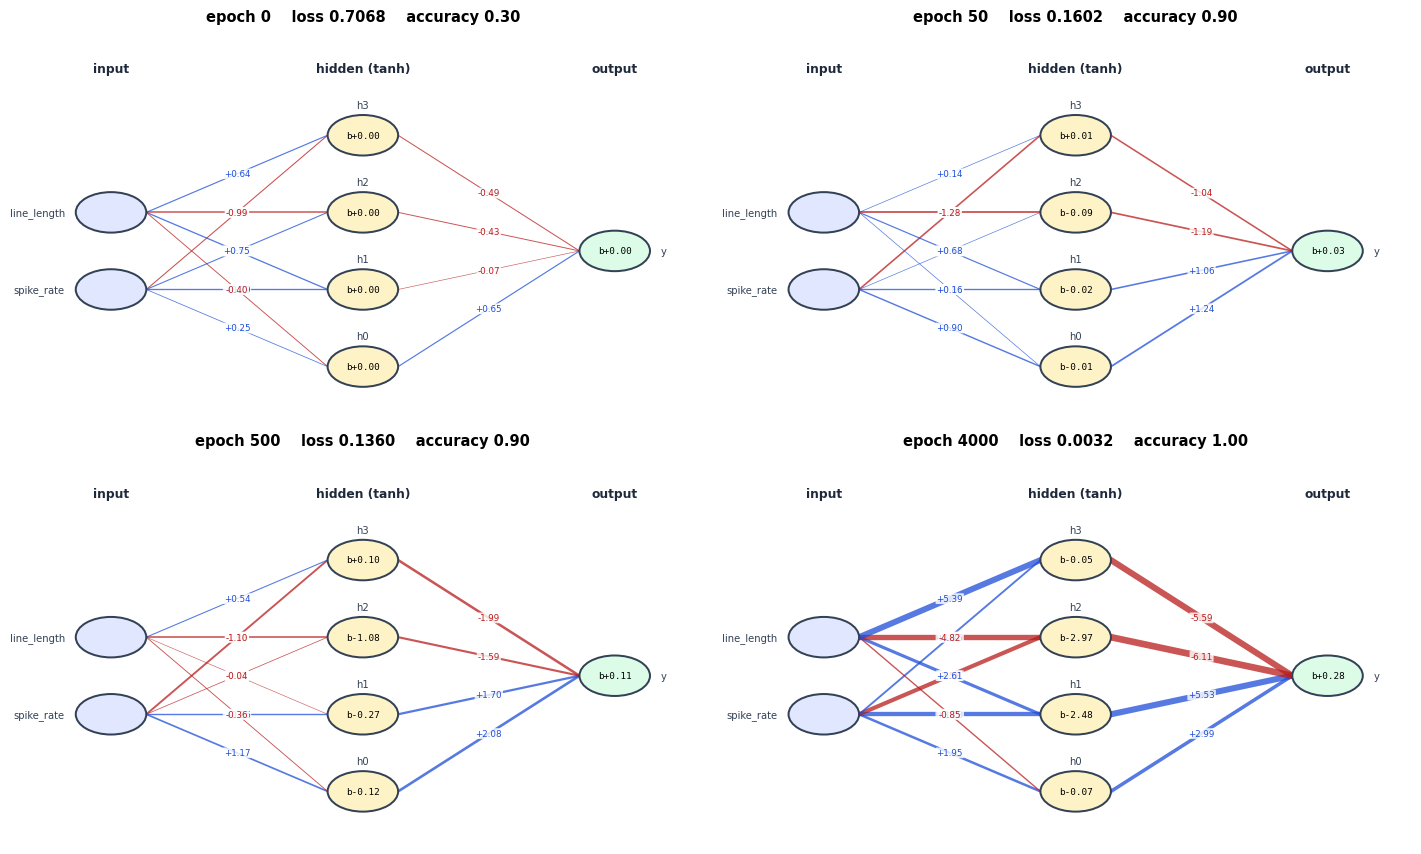

how the 17 numbers move

  epoch       loss     ||W1||     ||W2||    max |w|   accuracy
------------------------------------------------------------
      0    0.70678     1.8465     0.9222     0.9895     0.3000
     50    0.16023     2.2045     2.2738     1.2835     0.9000
    500    0.13604     2.3822     3.7038     2.0816     0.9000
   4000    0.00323     9.6237    10.3979     6.1111     1.0000
------------------------------------------------------------

At epoch 0 the edges are thin and evenly random - the network has no
opinion. As training proceeds some connections thicken into the ones that
carry the decision, and others fade toward zero. Nothing is added or
removed; the same 17 numbers simply take on useful values.


In [10]:
def snapshot(epochs_at, eta=0.5, seed=7):
    """Train and keep the weights at chosen epochs."""
    W1_, b1_, W2_, b2_ = init_params(seed)
    snaps, losses_ = {}, {}
    for ep in range(max(epochs_at) + 1):
        if ep in epochs_at:
            snaps[ep] = (W1_.copy(), b1_.copy(), W2_.copy(), b2_.copy())
            _, _, _, yh_ = forward(Pz, W1_, b1_, W2_, b2_)
            losses_[ep] = bce(yh_, Y)
        z1_, a1_, z2_, yh_ = forward(Pz, W1_, b1_, W2_, b2_)
        gW1_, gb1_, gW2_, gb2_, _, _ = backward(Pz, Y, z1_, a1_, z2_, yh_, W2_)
        W1_ -= eta*gW1_; b1_ -= eta*gb1_
        W2_ -= eta*gW2_; b2_ -= eta*gb2_
    return snaps, losses_

EPOCHS_SHOWN = [0, 50, 500, 4000]
snaps, snap_loss = snapshot(EPOCHS_SHOWN)

wmax_all = max(max(np.abs(s[0]).max(), np.abs(s[2]).max()) for s in snaps.values())

fig, axes = plt.subplots(2, 2, figsize=(15, 9))
for ax, ep in zip(axes.ravel(), EPOCHS_SHOWN):
    sW1, sb1, sW2, sb2 = snaps[ep]
    _, _, _, yh_e = forward(Pz, sW1, sb1, sW2, sb2)
    acc = float(((yh_e > .5).astype(int) == Y).mean())
    draw_network([N_IN, N_HID, N_OUT], [sW1, sW2], [sb1, sb2],
                 title=f"epoch {ep}    loss {snap_loss[ep]:.4f}    accuracy {acc:.2f}",
                 layer_names=["input", "hidden (tanh)", "output"],
                 node_labels=[feat2, [f"h{j}" for j in range(N_HID)], ["y"]],
                 ax=ax, wmax=wmax_all)
plt.tight_layout(); plt.show()

print("how the 17 numbers move\n")
print(f"{'epoch':>7}  {'loss':>9}  {'||W1||':>9}  {'||W2||':>9}  "
      f"{'max |w|':>9}  {'accuracy':>9}")
print("-" * 60)
for ep in EPOCHS_SHOWN:
    sW1, sb1, sW2, sb2 = snaps[ep]
    _, _, _, yh_e = forward(Pz, sW1, sb1, sW2, sb2)
    print(f"{ep:>7}  {snap_loss[ep]:>9.5f}  {np.linalg.norm(sW1):>9.4f}  "
          f"{np.linalg.norm(sW2):>9.4f}  "
          f"{max(np.abs(sW1).max(), np.abs(sW2).max()):>9.4f}  "
          f"{float(((yh_e>.5).astype(int)==Y).mean()):>9.4f}")
print("-" * 60)
print("\nAt epoch 0 the edges are thin and evenly random - the network has no")
print("opinion. As training proceeds some connections thicken into the ones that")
print("carry the decision, and others fade toward zero. Nothing is added or")
print("removed; the same 17 numbers simply take on useful values.")

### One epoch, every number

The same loop as the Linear Regression walkthrough &mdash; predict, measure error, get the
gradient, step &mdash; but now with two layers. Three epochs are traced in full, showing every
weight before and after.

In [11]:
eW1, eb1, eW2, eb2 = init_params(7)
ETA_TRACE = 0.5

for epoch in range(1, 4):
    z1_, a1_, z2_, yh_ = forward(Pz, eW1, eb1, eW2, eb2)
    L = bce(yh_, Y)
    gW1_, gb1_, gW2_, gb2_, d1_, d2_ = backward(Pz, Y, z1_, a1_, z2_, yh_, eW2)

    print("=" * 78)
    print(f"  EPOCH {epoch}        loss = {L:.6f}")
    print("=" * 78)

    print(f"\nFORWARD - what the network currently predicts (first 5 of {n2})\n")
    print(f"{'id':>6}  " + "  ".join(f"{'a1['+str(j)+']':>9}" for j in range(N_HID)) +
          f"  {'y_hat':>9}  {'y':>4}  {'error':>9}")
    print("-" * 74)
    for i in range(5):
        print(f"{ep_ids[i]:>6}  " + "  ".join(f"{a1_[i,j]:>9.5f}" for j in range(N_HID)) +
              f"  {yh_[i,0]:>9.5f}  {int(Y[i,0]):>4}  {yh_[i,0]-Y[i,0]:>9.5f}")
    print("-" * 74)

    print(f"\nBACKWARD - blame, layer by layer\n")
    print(f"   delta_2 (output)  : mean {d2_.mean():+.6f},  "
          f"largest |.| {np.abs(d2_).max():.6f}")
    print(f"   delta_1 (hidden)  : " +
          "  ".join(f"h{j}={d1_[:,j].mean():+.6f}" for j in range(N_HID)))

    print(f"\nGRADIENTS\n")
    print(f"{'':>14}  " + "  ".join(f"{'h'+str(j):>11}" for j in range(N_HID)))
    print("-" * 62)
    for r, nm in enumerate(feat2):
        print(f"   dL/dW1[{nm[:6]:>6}]  " +
              "  ".join(f"{gW1_[r,j]:>11.7f}" for j in range(N_HID)))
    print(f"   dL/db1{'':>8}  " + "  ".join(f"{gb1_[0,j]:>11.7f}" for j in range(N_HID)))
    print(f"   dL/dW2{'':>8}  " + "  ".join(f"{gW2_[j,0]:>11.7f}" for j in range(N_HID)))
    print(f"   dL/db2{'':>8}  {gb2_[0,0]:>11.7f}")
    print("-" * 62)

    print(f"\nUPDATE   w <- w - {ETA_TRACE} * gradient\n")
    print(f"{'weight':>16}  {'before':>11}  {'- eta*grad':>12}  {'after':>11}")
    print("-" * 56)
    for r, nm in enumerate(feat2):
        for j in range(N_HID):
            new = eW1[r,j] - ETA_TRACE*gW1_[r,j]
            print(f"{'W1['+nm[:4]+',h'+str(j)+']':>16}  {eW1[r,j]:>11.6f}  "
                  f"{-ETA_TRACE*gW1_[r,j]:>12.7f}  {new:>11.6f}")
    for j in range(N_HID):
        new = eW2[j,0] - ETA_TRACE*gW2_[j,0]
        print(f"{'W2[h'+str(j)+',y]':>16}  {eW2[j,0]:>11.6f}  "
              f"{-ETA_TRACE*gW2_[j,0]:>12.7f}  {new:>11.6f}")
    print(f"{'b2':>16}  {eb2[0,0]:>11.6f}  {-ETA_TRACE*gb2_[0,0]:>12.7f}  "
          f"{eb2[0,0]-ETA_TRACE*gb2_[0,0]:>11.6f}")
    print("-" * 56)

    eW1 -= ETA_TRACE*gW1_; eb1 -= ETA_TRACE*gb1_
    eW2 -= ETA_TRACE*gW2_; eb2 -= ETA_TRACE*gb2_
    _, _, _, yh_n = forward(Pz, eW1, eb1, eW2, eb2)
    print(f"\n   loss: {L:.6f}  ->  {bce(yh_n, Y):.6f}\n")

  EPOCH 1        loss = 0.706776

FORWARD - what the network currently predicts (first 5 of 20)

    id      a1[0]      a1[1]      a1[2]      a1[3]      y_hat     y      error
--------------------------------------------------------------------------
  ep00    0.19741   -0.96102    0.52316   -0.13556    0.50901     0    0.50901
  ep01    0.17000   -0.92327    0.45781   -0.12465    0.50961     0    0.50961
  ep02    0.19711   -0.97081    0.52837   -0.11811    0.50645     0    0.50645
  ep03    0.13275   -0.85999    0.36866   -0.09251    0.50816     0    0.50816
  ep04    0.16971   -0.94226    0.46348   -0.10716    0.50716     0    0.50716
--------------------------------------------------------------------------

BACKWARD - blame, layer by layer

   delta_2 (output)  : mean -0.000031,  largest |.| 0.027665
   delta_1 (hidden)  : h0=+0.000064  h1=+0.000001  h2=-0.000105  h3=-0.000189

GRADIENTS

                         h0           h1           h2           h3
--------------------------

### The boundary forming, epoch by epoch

The same training run seen from the outside: what the network actually predicts across
the whole feature space as its weights change.

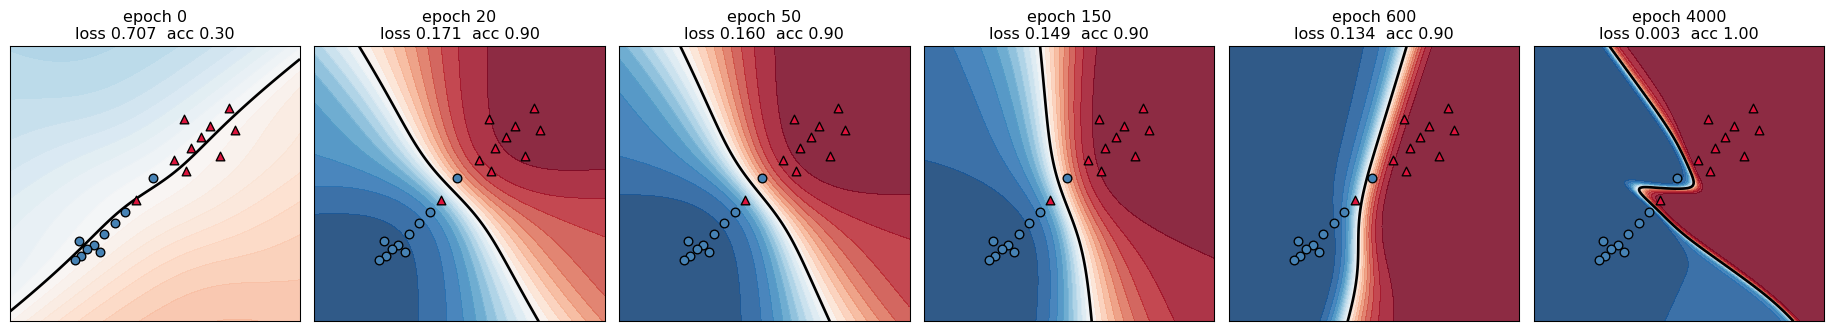

  epoch       loss   accuracy                                  what changed
----------------------------------------------------------------------------
      0    0.70678     0.3000           random weights, no structure at all
     20    0.17085     0.9000                  a rough linear split appears
     50    0.16023     0.9000                            the split sharpens
    150    0.14905     0.9000                   the boundary starts to bend
    600    0.13429     0.9000         curvature captures the awkward epochs
   4000    0.00323     1.0000                                     converged
----------------------------------------------------------------------------


In [12]:
gx0, gy0 = np.meshgrid(np.linspace(Pz[:,0].min()-1.2, Pz[:,0].max()+1.2, 220),
                       np.linspace(Pz[:,1].min()-1.2, Pz[:,1].max()+1.2, 220))
G0 = np.column_stack([gx0.ravel(), gy0.ravel()])

stages = [0, 20, 50, 150, 600, 4000]
snaps2, loss2 = snapshot(stages)

fig, axes = plt.subplots(1, len(stages), figsize=(3.2*len(stages), 3.6))
for ax, ep in zip(axes, stages):
    sW1, sb1, sW2, sb2 = snaps2[ep]
    _, _, _, pg_ = forward(G0, sW1, sb1, sW2, sb2)
    pg_ = pg_.reshape(gx0.shape)
    ax.contourf(gx0, gy0, pg_, levels=20, cmap="RdBu_r", alpha=.85, vmin=0, vmax=1)
    ax.contour(gx0, gy0, pg_, levels=[.5], colors="k", linewidths=2)
    for c, (col, mk) in enumerate([("steelblue","o"), ("crimson","^")]):
        m = t2 == c
        ax.scatter(Pz[m,0], Pz[m,1], c=col, marker=mk, s=42, edgecolor="k", zorder=3)
    _, _, _, yh_e = forward(Pz, sW1, sb1, sW2, sb2)
    ax.set(title=f"epoch {ep}\nloss {loss2[ep]:.3f}  acc "
                 f"{float(((yh_e>.5).astype(int)==Y).mean()):.2f}",
           xticks=[], yticks=[])
plt.tight_layout(); plt.show()

print(f"{'epoch':>7}  {'loss':>9}  {'accuracy':>9}  {'what changed':>44}")
print("-" * 76)
notes = {0: "random weights, no structure at all",
         20: "a rough linear split appears",
         50: "the split sharpens",
         150: "the boundary starts to bend",
         600: "curvature captures the awkward epochs",
         4000: "converged"}
for ep in stages:
    sW1, sb1, sW2, sb2 = snaps2[ep]
    _, _, _, yh_e = forward(Pz, sW1, sb1, sW2, sb2)
    print(f"{ep:>7}  {loss2[ep]:>9.5f}  "
          f"{float(((yh_e>.5).astype(int)==Y).mean()):>9.4f}  {notes[ep]:>44}")
print("-" * 76)

In [13]:
_, _, _, _ = forward(Pz, tW1, tb1, tW2, tb2)

_, _, _, yh_f = forward(Pz, tW1, tb1, tW2, tb2)
pred = (yh_f > .5).astype(int)
print(f"\nfinal loss     : {hist[-1]:.6f}")
print(f"final accuracy : {(pred == Y).mean():.4f}  ({int((pred==Y).sum())}/{n2})")
wrong = np.where(pred.ravel() != t2)[0]
print(f"misclassified  : {[ep_ids[i] for i in wrong] if len(wrong) else 'none'}")
print(f"\nLogistic regression got 18/20 on this data and could not do better -")
print(f"its boundary is a straight line. The hidden layer removes that limit.")


final loss     : 0.003226
final accuracy : 1.0000  (20/20)
misclassified  : none

Logistic regression got 18/20 on this data and could not do better -
its boundary is a straight line. The hidden layer removes that limit.


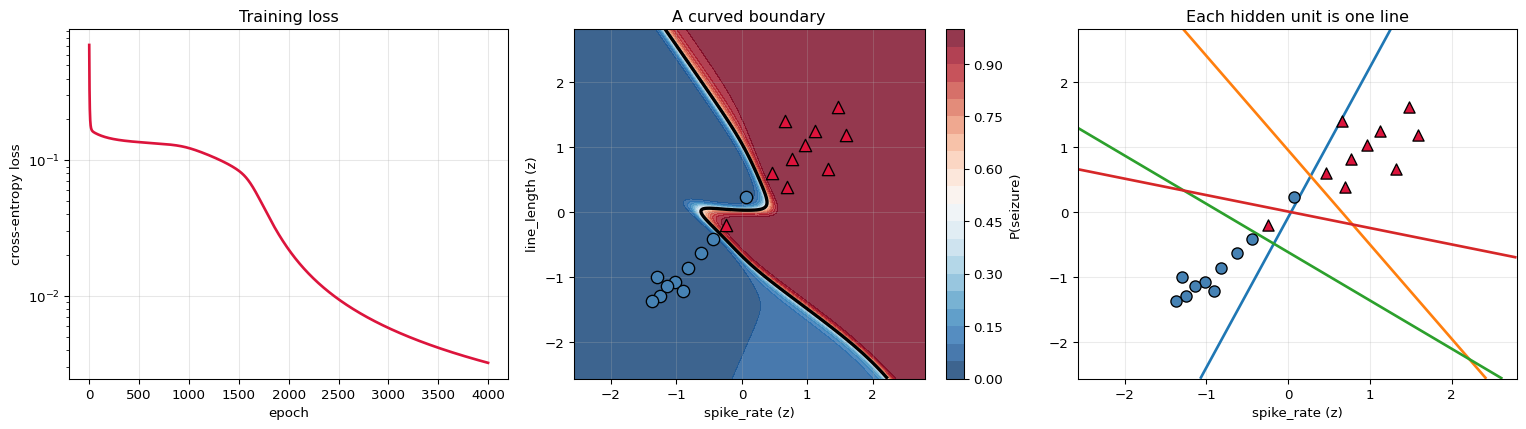

Right panel: each coloured line is where one hidden unit switches sign -
each is still LINEAR. The output layer combines these four half-planes,
and the tanh between them is what lets the combination bend.


In [14]:
gx, gy = np.meshgrid(np.linspace(Pz[:,0].min()-1.2, Pz[:,0].max()+1.2, 320),
                     np.linspace(Pz[:,1].min()-1.2, Pz[:,1].max()+1.2, 320))
G = np.column_stack([gx.ravel(), gy.ravel()])
_, _, _, pg = forward(G, tW1, tb1, tW2, tb2)
pg = pg.reshape(gx.shape)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
axes[0].plot(hist, lw=2, color="crimson")
axes[0].set(xlabel="epoch", ylabel="cross-entropy loss", yscale="log",
            title="Training loss")
axes[0].grid(alpha=.3)

cf = axes[1].contourf(gx, gy, pg, levels=20, cmap="RdBu_r", alpha=.8, vmin=0, vmax=1)
axes[1].contour(gx, gy, pg, levels=[.5], colors="k", linewidths=2.5)
plt.colorbar(cf, ax=axes[1], label="P(seizure)")
for c, (col, mk) in enumerate([("steelblue","o"), ("crimson","^")]):
    m = t2 == c
    axes[1].scatter(Pz[m,0], Pz[m,1], c=col, marker=mk, s=85, edgecolor="k", zorder=3)
axes[1].set(xlabel=feat2[0]+" (z)", ylabel=feat2[1]+" (z)",
            title="A curved boundary")
axes[1].grid(alpha=.25)

_, a1_g, _, _ = forward(G, tW1, tb1, tW2, tb2)
for j in range(N_HID):
    axes[2].contour(gx, gy, a1_g[:, j].reshape(gx.shape), levels=[0],
                    colors=[f"C{j}"], linewidths=2)
for c, (col, mk) in enumerate([("steelblue","o"), ("crimson","^")]):
    m = t2 == c
    axes[2].scatter(Pz[m,0], Pz[m,1], c=col, marker=mk, s=70, edgecolor="k", zorder=3)
axes[2].set(xlabel=feat2[0]+" (z)", title="Each hidden unit is one line")
axes[2].grid(alpha=.25)
plt.tight_layout(); plt.show()

print("Right panel: each coloured line is where one hidden unit switches sign -")
print("each is still LINEAR. The output layer combines these four half-planes,")
print("and the tanh between them is what lets the combination bend.")

### Why the non-linearity is essential

Replace $\tanh$ with the identity and the network becomes a product of matrices &mdash; an
expensive way to write logistic regression. The comparison below makes the collapse
concrete.

In [15]:
def train_linear(eta=0.5, epochs=4000, seed=7):
    W1_, b1_, W2_, b2_ = init_params(seed)
    for _ in range(epochs):
        z1_ = Pz @ W1_ + b1_
        a1_ = z1_                                # identity instead of tanh
        z2_ = a1_ @ W2_ + b2_
        yh_ = sigmoid(z2_)
        n = len(Pz)
        d2_ = (yh_ - Y)/n
        gW2_ = a1_.T @ d2_; gb2_ = d2_.sum(axis=0, keepdims=True)
        d1_ = d2_ @ W2_.T                        # derivative of identity is 1
        gW1_ = Pz.T @ d1_; gb1_ = d1_.sum(axis=0, keepdims=True)
        W1_ -= eta*gW1_; b1_ -= eta*gb1_; W2_ -= eta*gW2_; b2_ -= eta*gb2_
    z1_ = Pz @ W1_ + b1_
    yh_ = sigmoid(z1_ @ W2_ + b2_)
    return W1_, b1_, W2_, b2_, yh_

lW1, lb1, lW2, lb2, lyh = train_linear()
lpred = (lyh > .5).astype(int)

from sklearn.linear_model import LogisticRegression
logreg = LogisticRegression(C=np.inf, max_iter=10000).fit(Pz, t2)

print(f"{'model':>34}  {'loss':>10}  {'accuracy':>9}")
print("-" * 58)
print(f"{'2-layer, tanh hidden':>34}  {hist[-1]:>10.6f}  {(pred==Y).mean():>9.4f}")
print(f"{'2-layer, NO non-linearity':>34}  {bce(lyh, Y):>10.6f}  {(lpred==Y).mean():>9.4f}")
print(f"{'plain logistic regression':>34}  "
      f"{bce(logreg.predict_proba(Pz)[:,1:2], Y):>10.6f}  "
      f"{logreg.score(Pz, t2):>9.4f}")
print("-" * 58)

W_eff = lW1 @ lW2
print(f"\nthe linear network's effective single weight vector W1 @ W2:")
print(f"   {np.round(W_eff.ravel(), 6)}   (bias {(lb1 @ lW2 + lb2).item():+.6f})")
print(f"   direction, normalised : {np.round(W_eff.ravel()/np.linalg.norm(W_eff), 6)}")
print(f"   logistic regression   : {np.round(logreg.coef_[0]/np.linalg.norm(logreg.coef_[0]), 6)}")
cos = abs(float(W_eff.ravel() @ logreg.coef_[0]) /
          (np.linalg.norm(W_eff) * np.linalg.norm(logreg.coef_[0])))
print(f"   cosine similarity     : {cos:.8f}")
print(f"\nThe 17-parameter linear network found the SAME direction as the")
print(f"3-parameter logistic regression, because that is all it can express.")
print(f"Two linear layers are one linear layer.")

                             model        loss   accuracy
----------------------------------------------------------
              2-layer, tanh hidden    0.003226     1.0000
         2-layer, NO non-linearity    0.132144     0.9000
         plain logistic regression    0.132145     0.9000
----------------------------------------------------------

the linear network's effective single weight vector W1 @ W2:
   [ 8.8381 -2.9434]   (bias +0.660633)
   direction, normalised : [ 0.9488 -0.316 ]
   logistic regression   : [ 0.9482 -0.3177]
   cosine similarity     : 0.99999834

The 17-parameter linear network found the SAME direction as the
3-parameter logistic regression, because that is all it can express.
Two linear layers are one linear layer.


---
# 6. Activations and Vanishing Gradients

$\delta$ is multiplied by the activation's derivative at every layer. If that derivative
is habitually smaller than 1, the product shrinks geometrically with depth &mdash; the
**vanishing gradient** problem, and the reason deep networks were impractical before ReLU.

| Activation | $f(z)$ | $f'(z)$ | max $f'$ |
|---|---|---|---|
| Sigmoid | $1/(1+e^{-z})$ | $f(1-f)$ | **0.25** |
| Tanh | $\tanh z$ | $1 - f^2$ | **1.0** |
| ReLU | $\max(0,z)$ | $0$ or $1$ | **1.0** |

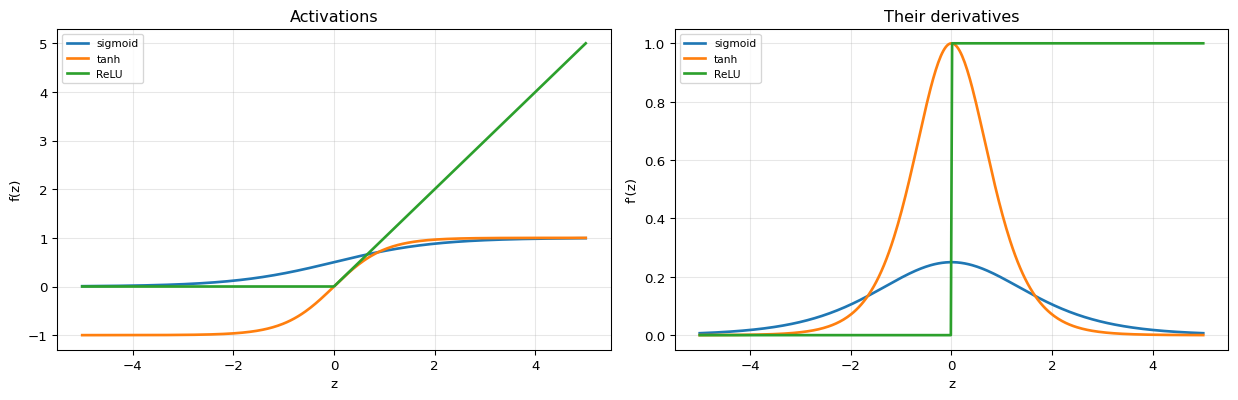

what happens to a gradient passed back through L layers

 layers         sigmoid            tanh            ReLU
--------------------------------------------------------
      1       2.500e-01       9.998e-01       1.000e+00
      5       9.764e-04       9.992e-01       1.000e+00
     10       9.533e-07       9.984e-01       1.000e+00
     25       8.873e-16       9.961e-01       1.000e+00
     50       7.873e-31       9.922e-01       1.000e+00
--------------------------------------------------------

With sigmoid the BEST case is 0.25 per layer, so after 25 layers the
gradient is ~1e-15 - numerically zero. Early layers stop learning.
tanh and ReLU have a maximum derivative of 1, which is why they replaced it.


same network, three activations, 2000 epochs each:

  activation    final loss   accuracy
--------------------------------------
        tanh      0.022045     1.0000
     sigmoid      0.137789     0.9000
        ReLU      0.115094     0.9500
----------------------------------

In [16]:
zg = np.linspace(-5, 5, 400)
acts = {
    "sigmoid": (sigmoid(zg), sigmoid(zg)*(1-sigmoid(zg))),
    "tanh": (np.tanh(zg), 1-np.tanh(zg)**2),
    "ReLU": (np.maximum(0, zg), (zg > 0).astype(float)),
}
fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
for nm, (f_, d_) in acts.items():
    axes[0].plot(zg, f_, lw=2, label=nm)
    axes[1].plot(zg, d_, lw=2, label=nm)
axes[0].set(xlabel="z", ylabel="f(z)", title="Activations"); axes[0].legend(fontsize=8)
axes[1].set(xlabel="z", ylabel="f'(z)", title="Their derivatives")
axes[1].legend(fontsize=8)
for a in axes: a.grid(alpha=.3)
plt.tight_layout(); plt.show()

print("what happens to a gradient passed back through L layers\n")
print(f"{'layers':>7}  " + "  ".join(f"{k:>14}" for k in acts))
print("-" * 56)
for L in (1, 5, 10, 25, 50):
    row = []
    for nm, (_, d_) in acts.items():
        row.append(d_.max() ** L)
    print(f"{L:>7}  " + "  ".join(f"{v:>14.3e}" for v in row))
print("-" * 56)
print("\nWith sigmoid the BEST case is 0.25 per layer, so after 25 layers the")
print("gradient is ~1e-15 - numerically zero. Early layers stop learning.")
print("tanh and ReLU have a maximum derivative of 1, which is why they replaced it.")

print(f"\n\nsame network, three activations, {2000} epochs each:\n")
def train_act(act, dact, eta=0.5, epochs=2000, seed=7):
    W1_, b1_, W2_, b2_ = init_params(seed)
    for _ in range(epochs):
        z1_ = Pz @ W1_ + b1_; a1_ = act(z1_)
        yh_ = sigmoid(a1_ @ W2_ + b2_)
        n = len(Pz); d2_ = (yh_-Y)/n
        gW2_ = a1_.T @ d2_; gb2_ = d2_.sum(axis=0, keepdims=True)
        d1_ = (d2_ @ W2_.T) * dact(z1_, a1_)
        W1_ -= eta*(Pz.T @ d1_); b1_ -= eta*d1_.sum(axis=0, keepdims=True)
        W2_ -= eta*gW2_; b2_ -= eta*gb2_
    z1_ = Pz @ W1_ + b1_
    yh_ = sigmoid(act(z1_) @ W2_ + b2_)
    return bce(yh_, Y), ((yh_ > .5).astype(int) == Y).mean()

print(f"{'activation':>12}  {'final loss':>12}  {'accuracy':>9}")
print("-" * 38)
for nm, act, dact in [
    ("tanh", np.tanh, lambda z, a: 1-a**2),
    ("sigmoid", sigmoid, lambda z, a: a*(1-a)),
    ("ReLU", lambda z: np.maximum(0, z), lambda z, a: (z > 0).astype(float)),
]:
    L, acc = train_act(act, dact)
    print(f"{nm:>12}  {L:>12.6f}  {acc:>9.4f}")
print("-" * 38)

---
# 7. Capacity

The **universal approximation theorem** says one hidden layer with enough units can
approximate any continuous function to arbitrary accuracy. It says nothing about how many
units, or whether gradient descent will find them &mdash; and it comes with the usual price:
enough capacity to fit anything includes enough capacity to fit noise.

 hidden units   parameters    final loss   train acc
----------------------------------------------------
            1            5      0.135725      0.9000
            2            9      0.134148      0.9000
            4           17      0.005833      1.0000
            8           33      0.133313      0.9000
           16           65      0.133089      0.9000
           32          129      0.132797      0.9000
----------------------------------------------------

20 training points and up to 129 parameters - far more knobs
than data. On a real problem that gap is where overfitting lives; here it
is only being used to show the capacity dial working.


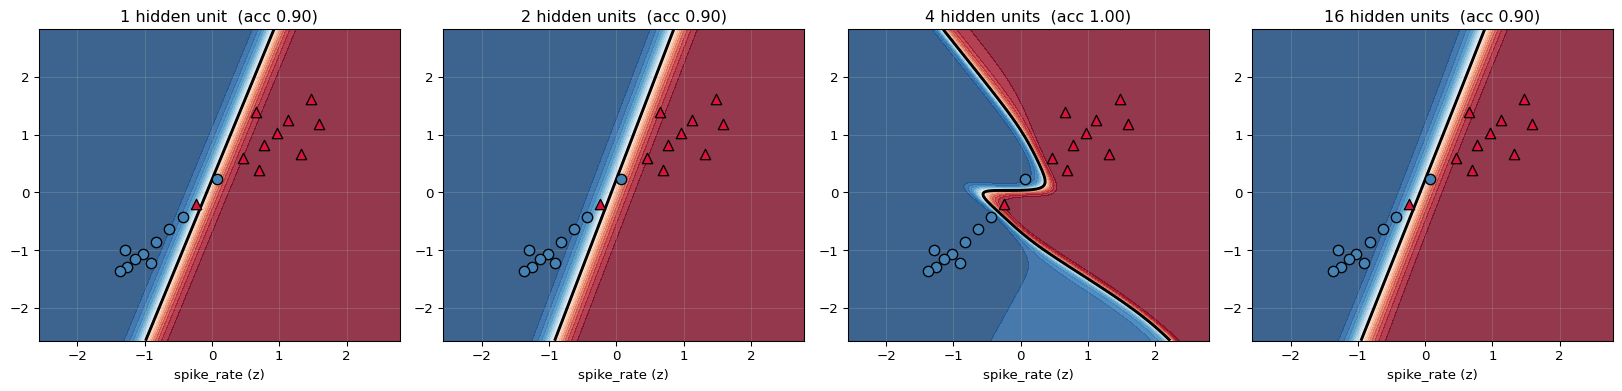

One hidden unit can only produce a straight boundary - it is logistic
regression again. Two can bend it. Sixteen wraps tightly around the
individual awkward points, which is memorisation, not understanding.


In [17]:
print(f"{'hidden units':>13}  {'parameters':>11}  {'final loss':>12}  {'train acc':>10}")
print("-" * 52)
for h in (1, 2, 4, 8, 16, 32):
    globals()['N_HID'] = h
    (aW1, ab1, aW2, ab2), hh = train(epochs=3000)
    _, _, _, ayh = forward(Pz, aW1, ab1, aW2, ab2)
    npar = 2*h + h + h*1 + 1
    print(f"{h:>13}  {npar:>11}  {hh[-1]:>12.6f}  "
          f"{((ayh > .5).astype(int) == Y).mean():>10.4f}")
globals()['N_HID'] = 4
print("-" * 52)
print(f"\n{n2} training points and up to {2*32+32+32+1} parameters - far more knobs")
print(f"than data. On a real problem that gap is where overfitting lives; here it")
print(f"is only being used to show the capacity dial working.")

fig, axes = plt.subplots(1, 4, figsize=(17, 4.2))
for ax, h in zip(axes, (1, 2, 4, 16)):
    globals()['N_HID'] = h
    (aW1, ab1, aW2, ab2), _ = train(epochs=3000)
    _, _, _, pgh = forward(G, aW1, ab1, aW2, ab2)
    pgh = pgh.reshape(gx.shape)
    ax.contourf(gx, gy, pgh, levels=20, cmap="RdBu_r", alpha=.8, vmin=0, vmax=1)
    ax.contour(gx, gy, pgh, levels=[.5], colors="k", linewidths=2.2)
    for c, (col, mk) in enumerate([("steelblue","o"), ("crimson","^")]):
        m = t2 == c
        ax.scatter(Pz[m,0], Pz[m,1], c=col, marker=mk, s=60, edgecolor="k", zorder=3)
    _, _, _, ayh = forward(Pz, aW1, ab1, aW2, ab2)
    ax.set(title=f"{h} hidden unit{'s' if h>1 else ''}  "
                 f"(acc {((ayh>.5).astype(int)==Y).mean():.2f})",
           xlabel=feat2[0]+" (z)")
    ax.grid(alpha=.25)
globals()['N_HID'] = 4
plt.tight_layout(); plt.show()

print("One hidden unit can only produce a straight boundary - it is logistic")
print("regression again. Two can bend it. Sixteen wraps tightly around the")
print("individual awkward points, which is memorisation, not understanding.")

---
# 8. Checking Against scikit-learn

`MLPClassifier` will not reproduce our exact weights &mdash; different initialisation, a
different optimiser, and its own regularisation. What *can* be checked is that the same
architecture reaches the same quality, and that our forward pass reproduces sklearn's
outputs when handed **sklearn's own trained weights**.

In [18]:
from sklearn.neural_network import MLPClassifier

mlp = MLPClassifier(hidden_layer_sizes=(4,), activation="tanh", solver="lbfgs",
                    alpha=1e-6, max_iter=5000, random_state=0).fit(Pz, t2)

print(f"{'model':>28}  {'accuracy':>9}  {'loss':>10}")
print("-" * 52)
print(f"{'ours (hand-written)':>28}  {(pred==Y).mean():>9.4f}  {hist[-1]:>10.6f}")
print(f"{'sklearn MLPClassifier':>28}  {mlp.score(Pz, t2):>9.4f}  "
      f"{bce(mlp.predict_proba(Pz)[:,1:2], Y):>10.6f}")
print("-" * 52)

print(f"\nnow run OUR forward pass using SKLEARN's trained weights:\n")
sW1, sW2 = mlp.coefs_
sb1, sb2 = mlp.intercepts_
print(f"   W1 {sW1.shape}, b1 {sb1.shape}, W2 {sW2.shape}, b2 {sb2.shape}")

_, _, _, our_out = forward(Pz, sW1, sb1.reshape(1,-1), sW2, sb2.reshape(1,-1))
sk_out = mlp.predict_proba(Pz)[:, 1:2]

print(f"\n{'id':>6}  {'our forward':>14}  {'sklearn proba':>15}  {'diff':>10}")
print("-" * 52)
for i in range(8):
    print(f"{ep_ids[i]:>6}  {our_out[i,0]:>14.10f}  {sk_out[i,0]:>15.10f}  "
          f"{abs(our_out[i,0]-sk_out[i,0]):>10.2e}")
print(f"{'...':>6}")
print("-" * 52)
print(f"\nall {n2} outputs MATCH: {np.allclose(our_out, sk_out, atol=1e-10)}")
print(f"max difference: {np.abs(our_out - sk_out).max():.3e}")
print(f"\nThat confirms the forward pass is exactly the operation sklearn performs.")
print(f"The gradient check in section 4 confirms the backward pass. Together they")
print(f"establish the implementation, without needing identical weights.")

                       model   accuracy        loss
----------------------------------------------------
         ours (hand-written)     1.0000    0.003226
       sklearn MLPClassifier     1.0000    0.000027
----------------------------------------------------

now run OUR forward pass using SKLEARN's trained weights:

   W1 (2, 4), b1 (4,), W2 (4, 1), b2 (1,)

    id     our forward    sklearn proba        diff
----------------------------------------------------
  ep00    0.0000020880     0.0000020880    0.00e+00
  ep01    0.0000028418     0.0000028418    0.00e+00
  ep02    0.0000018323     0.0000018323    0.00e+00
  ep03    0.0000051654     0.0000051654    8.47e-22
  ep04    0.0000020440     0.0000020440    4.24e-22
  ep05    0.0000184342     0.0000184342    3.39e-21
  ep06    0.0000000000     0.0000000000    0.00e+00
  ep07    0.0000082756     0.0000082756    1.69e-21
   ...
----------------------------------------------------

all 20 outputs MATCH: True
max difference: 5.421e-20


---
# 9. Summary

| Stage | Formula |
|---|---|
| Forward, layer 1 | $\mathbf{z}_1 = XW_1+\mathbf{b}_1$, $\;\mathbf{a}_1 = \tanh\mathbf{z}_1$ |
| Forward, layer 2 | $z_2 = \mathbf{a}_1W_2+b_2$, $\;\hat{y} = \sigma(z_2)$ |
| Loss | binary cross-entropy |
| Output blame | $\delta_2 = \hat{y}-y$ |
| Hidden blame | $\delta_1 = (\delta_2W_2^\top)\odot(1-\mathbf{a}_1^2)$ |
| Gradients | $\frac{1}{n}\mathbf{a}_1^\top\delta_2$, $\;\frac{1}{n}X^\top\delta_1$ |
| Update | $\theta \leftarrow \theta - \eta\nabla_\theta\mathcal{L}$ |
| Verification | central differences, rel. error $< 10^{-7}$ |

**The one idea:** backpropagation is the chain rule with the intermediate results kept.
A naive approach would recompute the shared prefix for every parameter; backprop computes
each $\delta$ once and reuses it, which is what makes the cost of the backward pass
roughly equal to the forward pass rather than proportional to the parameter count.

**What the non-linearity buys:** without it, depth is an illusion &mdash; section 5 shows a
17-parameter linear network converging to exactly the direction that 3-parameter logistic
regression finds. With it, the same network draws a boundary neither could.

**What is deliberately left out:** mini-batch SGD and momentum, Adam and adaptive
learning rates, dropout, batch normalisation, weight decay, learning-rate schedules,
softmax with multiple classes, convolutional and recurrent structure, and automatic
differentiation &mdash; which is this notebook's backward pass, generalised and generated
rather than derived by hand.